<div style="
background: linear-gradient(135deg,#0f2027,#203a43,#2c5364);
padding:60px;
font-family:Arial;
text-align:center;
border-radius:10px;
color:white;
">

<div style="
background:white;
color:#333;
padding:40px;
border-radius:12px;
width:70%;
margin:auto;
box-shadow:0px 10px 25px rgba(0,0,0,0.3);
">

<h1 style="color:#1a4f8b;">
Portfolio Construction, Technology, and Financial Data Analysis For Equity Group Holdings (Kenya) 
</h1>

<h2>For Equity Group Holdings</h2>

<hr>

<p><b>Module / Course Name:</b> Modern Portfolio Theory and Investment Analysis</p>
<p><b>Module Code:</b> BSA83812</p>

<h3 style="color:#1a4f8b;">Group 9 Members</h3>

<p>Bon Fils Ishimwe</p>
<p>Aliane Uwase</p>
<p>Venantie Uwimana</p>
<p>Shadia Uwimbabazi</p>

<hr>

<p><b>Cohort / Term:</b> KC-BA 2024 | Year 2, Term 3</p>
<p><b>Academic Year:</b> 2024–2025</p>
<p><b>Faculty:</b> Faculty of Management</p>
<p><b>Instructor:</b> Abel Baraka</p>

<h3>Group Presentation</h3>

</div>
</div>

## STEP1 :Load & Clean Data from Excel

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from scipy import stats

In [51]:
Equity_data=pd.read_excel(r"D:\EFI\BOOT\computer applications\Y2TERMIII\MPT\ASSIGNEMENT\Equity Group Holdings.xlsx")

In [52]:
Equity_data

,Date,Open,Low,High,Close,Volume
0,2026-03-13 00:00:00,77.75,76.50,77.75,77.0,5.37M
1,2026-03-12 00:00:00,77.00,76.00,78.50,77.0,3.35M
2,2026-03-11 00:00:00,75.50,74.75,77.00,75.5,3.65M
3,2026-03-10 00:00:00,74.00,73.50,75.50,74.0,4.81M
4,2026-03-09 00:00:00,75.00,73.00,75.50,74.0,3.28M
...,...,...,...,...,...,...
494,2024-03-15 00:00:00,42.30,41.60,44.00,42.6,611.30K
495,2024-03-14 00:00:00,40.40,40.40,42.30,41.6,147.20K
496,2024-03-13 00:00:00,40.00,40.00,41.00,40.2,628.10K
497,NaN,NaN,NaN,NaN,NaN,NaN


In [53]:
## To find the missing values in our data set 

In [54]:
Equity_data.isnull().sum()

Date      1
Open      2
Low       2
High      2
Close     2
Volume    2
dtype: int64

In [55]:
##  The statistical information about the historical price for the Equity Group Holdings  from 13, march,2024 up to  the 13,3,2026

In [56]:
### Convert Volume Column to Numeric

In [57]:
def parse_volume(v):
    if v is None:
        return np.nan
    if isinstance(v, (int, float)):
        return float(v)
    v_str = str(v).strip().upper()
    if 'M' in v_str:
        return float(v_str.replace('M','')) * 1_000_000
    if 'K' in v_str:
        return float(v_str.replace('K','')) * 1_000
    try:
        return float(v_str)
    except ValueError:
        return np.nan

Equity_data['Volume'] = Equity_data['Volume'].apply(parse_volume)

In [58]:
Equity_data['Volume']

0      5370000.0
1      3350000.0
2      3650000.0
3      4810000.0
4      3280000.0
         ...    
494     611300.0
495     147200.0
496     628100.0
497          NaN
498          NaN
Name: Volume, Length: 499, dtype: float64

In [59]:
##Check Data Types
Equity_data.dtypes

Date       object
Open      float64
Low       float64
High      float64
Close     float64
Volume    float64
dtype: object

In [60]:
# CALCULATE DAILY RETURNS 
# Use 'Close' price since there is no 'Adj Close' column
Equity_data['Return'] = Equity_data['Close'].pct_change()
Equity_data = Equity_data.dropna(subset=['Return'])  # drop first NaN return

C:\Users\Kepler\AppData\Local\Temp\ipykernel_8956\2458899813.py:3: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  Equity_data['Return'] = Equity_data['Close'].pct_change()


In [61]:
Equity_data['Return']

1      0.000000
2     -0.019481
3     -0.019868
4      0.000000
5      0.006757
         ...   
494   -0.005834
495   -0.023474
496   -0.033654
497    0.000000
498    0.000000
Name: Return, Length: 498, dtype: float64

## 📊 Step 2  Descriptive Statistics

In [63]:
import pandas as pd

#  ENSURE DATE IS DATETIME 
Equity_data['Date'] = pd.to_datetime(Equity_data['Date'], errors='coerce')

#  SUMMARY STATISTICS 
price = Equity_data['Close']
vol   = Equity_data['Volume'].dropna()

# Price statistics
stats = price.describe(percentiles=[0.25, 0.5, 0.75]).to_frame(name='Value')
stats.loc['Skewness']       = price.skew()
stats.loc['Excess Kurtosis'] = price.kurt()

# Total return and holding period
total_return = (price.iloc[-1] - price.iloc[0]) / price.iloc[0]
holding_days = (Equity_data['Date'].iloc[-1] - Equity_data['Date'].iloc[0]).days

# Volume and daily range
avg_range     = (Equity_data['High'] - Equity_data['Low']).mean()
avg_range_pct = ((Equity_data['High'] - Equity_data['Low']) / price).mean() * 100

# PRINT RESULTS
print(f"Total 2-Year Return (HPR) : {total_return*100:.4f}% over {holding_days} days")
print(f"Mean daily volume         : {vol.mean():,.0f} shares")
print(f"Median daily volume       : {vol.median():,.0f} shares")
print(f"Max daily volume          : {vol.max():,.0f} shares")
print(f"Avg daily range           : KES {avg_range:.4f} ({avg_range_pct:.4f}%)")
display(stats.round(4))

Total 2-Year Return (HPR) : nan% over nan days
Mean daily volume         : 1,548,724 shares
Median daily volume       : 634,370 shares
Max daily volume          : 27,660,000 shares
Avg daily range           : KES 1.3856 (2.7231%)


C:\Users\Kepler\AppData\Local\Temp\ipykernel_8956\3385060649.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Equity_data['Date'] = pd.to_datetime(Equity_data['Date'], errors='coerce')


,Value
count,496.0000
mean,51.0185
std,9.4025
min,38.5000
25%,44.2875
50%,47.7000
75%,55.5000
max,77.2500
Skewness,1.1615
Excess Kurtosis,0.3001


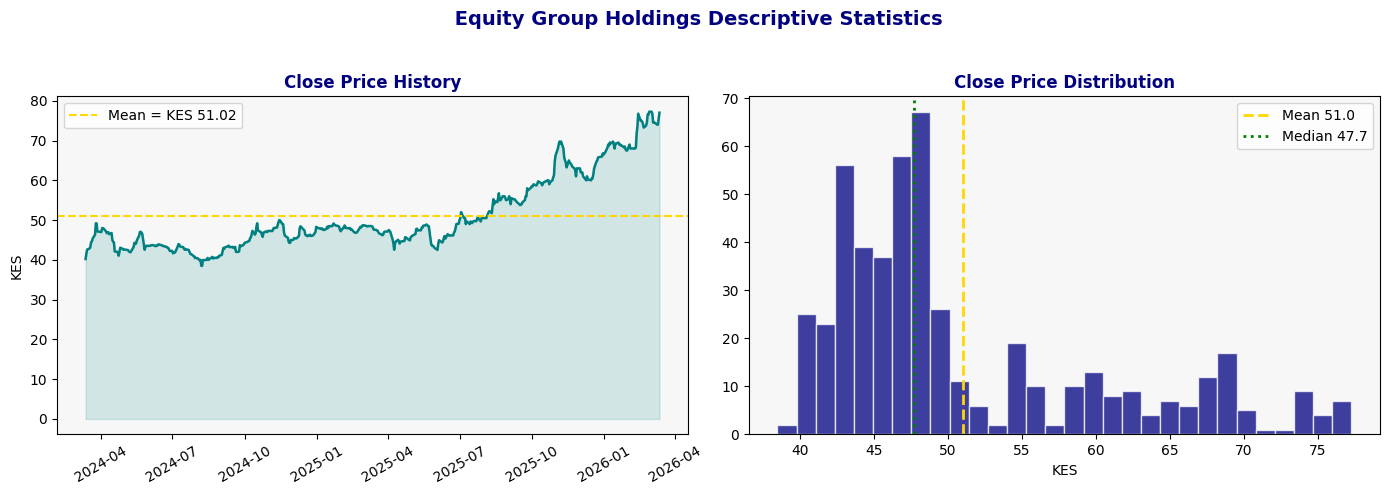

In [64]:
#  VISUALISATION
fig, axes = plt.subplots(1, 2, figsize=(14,5))
fig.suptitle(' Equity Group Holdings Descriptive Statistics', fontsize=14, fontweight='bold', color='navy')

# 1️ Close Price History
axes[0].plot(Equity_data['Date'], Equity_data['Close'], color='teal', lw=1.8)
axes[0].fill_between(Equity_data['Date'], Equity_data['Close'], alpha=0.15, color='teal')
axes[0].axhline(Equity_data['Close'].mean(), color='gold', linestyle='--', lw=1.5,label=f'Mean = KES {Equity_data["Close"].mean():.2f}')
axes[0].set_title('Close Price History', fontweight='bold', color='navy')
axes[0].set_ylabel('KES')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_facecolor('#f7f7f7')

#  Close Price Distribution
axes[1].hist(Equity_data['Close'], bins=30, color='navy', alpha=0.75, edgecolor='white')
axes[1].axvline(Equity_data['Close'].mean(), color='gold', linestyle='--', lw=2,label=f'Mean {Equity_data["Close"].mean():.1f}')
axes[1].axvline(Equity_data['Close'].median(), color='green', linestyle=':', lw=2, label=f'Median {Equity_data["Close"].median():.1f}')
axes[1].set_title('Close Price Distribution', fontweight='bold', color='navy')
axes[1].set_xlabel('KES')
axes[1].legend()
axes[1].set_facecolor('#f7f7f7')

plt.tight_layout(rect=[0,0,1,0.95])
plt.show()

C:\Users\Kepler\AppData\Local\Temp\ipykernel_8956\3983221009.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Equity_data['Daily_Range'] = Equity_data['High'] - Equity_data['Low']
C:\Users\Kepler\AppData\Local\Temp\ipykernel_8956\3983221009.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Equity_data['Daily_Range_Pct'] = Equity_data['Daily_Range'] / Equity_data['Close'] * 100


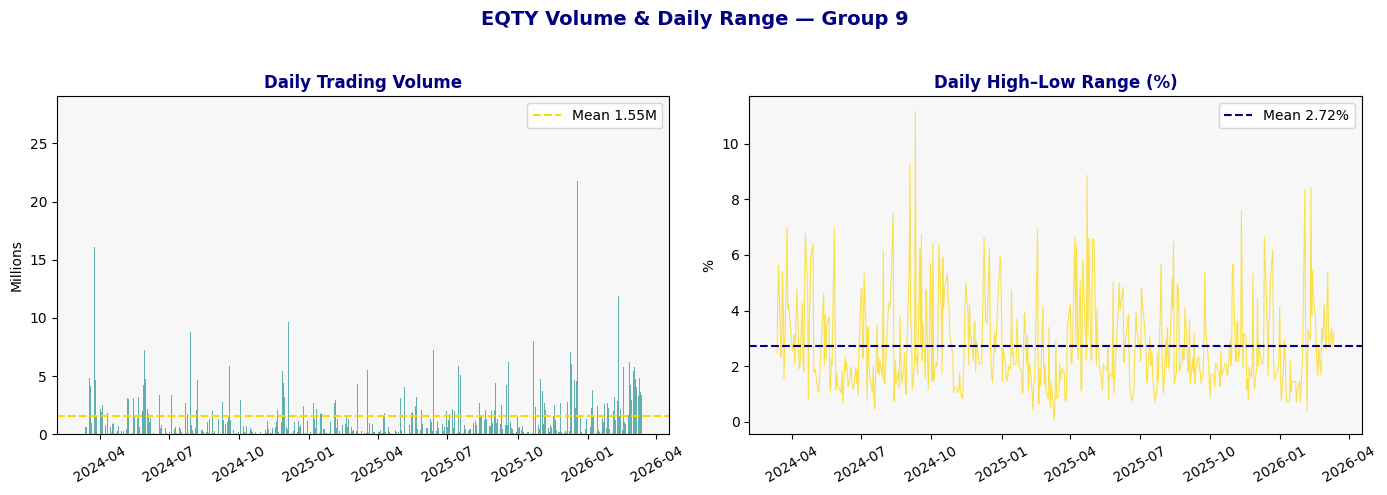

In [65]:

Equity_data['Daily_Range'] = Equity_data['High'] - Equity_data['Low']
Equity_data['Daily_Range_Pct'] = Equity_data['Daily_Range'] / Equity_data['Close'] * 100

#  VOLUME & DAILY RANGE VISUALIZATION 
fig, axes = plt.subplots(1, 2, figsize=(14,5))
fig.suptitle('EQTY Volume & Daily Range — Group 9', fontsize=14, fontweight='bold', color='navy')

# Daily Trading Volume (in millions)
axes[0].bar(Equity_data['Date'], Equity_data['Volume']/1e6, color='teal', alpha=0.6, width=1)
axes[0].axhline(Equity_data['Volume'].mean()/1e6, color='gold', linestyle='--', lw=1.5,
                label=f'Mean {Equity_data["Volume"].mean()/1e6:.2f}M')
axes[0].set_title('Daily Trading Volume', fontweight='bold', color='navy')
axes[0].set_ylabel('Millions')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_facecolor('#f7f7f7')

# Daily High–Low Range (%)
axes[1].plot(Equity_data['Date'], Equity_data['Daily_Range_Pct'], color='gold', lw=0.8, alpha=0.7)
axes[1].axhline(Equity_data['Daily_Range_Pct'].mean(), color='navy', linestyle='--', lw=1.5,
                label=f"Mean {Equity_data['Daily_Range_Pct'].mean():.2f}%")
axes[1].set_title('Daily High–Low Range (%)', fontweight='bold', color='navy')
axes[1].set_ylabel('%')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_facecolor('#f7f7f7')

plt.tight_layout(rect=[0,0,1,0.95])
plt.show()

## 📈 Step 3  Daily Arithmetic & Log Returns

**Formulae:**
$$r_t^{arith} = \frac{P_t - P_{t-1}}{P_{t-1}} \qquad r_t^{log} = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

**Difference:** Arithmetic returns are used in portfolio optimisation (linear additivity).  
Log returns are used in time-series modelling (temporal additivity).

In [ ]:
# ──COMPUTE DAILY RETURNS 
Equity_data['Return_Arith'] = Equity_data['Close'].pct_change()                 # Arithmetic return
Equity_data['Return_Log']   = np.log(Equity_data['Close'] / Equity_data['Close'].shift(1))  # Log return

# Remove NaN from first row
returns = Equity_data.dropna(subset=['Return_Arith']).reset_index(drop=True)

#  SHOW FIRST 10 CALCULATIONS 
print("First 10 daily return calculations:")
sample = returns[['Date','Close','Return_Arith','Return_Log']].head(10).copy()
sample['Return_Arith_%'] = sample['Return_Arith'] * 100
sample['Return_Log_%']   = sample['Return_Log'] * 100

display(sample[['Date','Close','Return_Arith_%','Return_Log_%']].round(4))

In [66]:
#  RETURN STATISTICS 
r_arith = returns['Return_Arith']
r_log   = returns['Return_Log']

stats_ret = pd.DataFrame({
    'Arithmetic': [r_arith.mean(), r_arith.median(), r_arith.std(),
                   r_arith.min(), r_arith.max(), r_arith.skew(), r_arith.kurt()],
    'Log Return': [r_log.mean(), r_log.median(), r_log.std(),
                   r_log.min(), r_log.max(), r_log.skew(), r_log.kurt()]
}, index=['Mean', 'Median', 'Std Dev', 'Min', 'Max', 'Skewness', 'Kurtosis'])

display(stats_ret.round(6))

print(f"\n  Positive days : {(r_arith > 0).sum()} ({(r_arith > 0).mean()*100:.1f}%)")
print(f"  Negative days : {(r_arith < 0).sum()} ({(r_arith < 0).mean()*100:.1f}%)")
print(f"  Zero days     : {(r_arith == 0).sum()}")

# Normality tests
stat_jb, p_jb = stats.jarque_bera(r_arith)
stat_sw, p_sw  = stats.shapiro(r_arith[:5000])
print(f"\n  Jarque-Bera : stat={stat_jb:.2f}, p={p_jb:.6f}  → {'NOT normal ✗' if p_jb<0.05 else 'Normal ✓'}")
print(f"  Shapiro-Wilk: stat={stat_sw:.4f}, p={p_sw:.6f}  → {'NOT normal ✗' if p_sw<0.05 else 'Normal ✓'}")


,Arithmetic,Log Return
Mean,0.001357,0.001244
Median,0.000000,0.000000
Std Dev,0.014989,0.015044
Min,-0.091847,-0.096343
Max,0.061489,0.059672
Skewness,-0.543274,-0.730140
Kurtosis,6.322669,7.114017



  Positive days : 223 (45.1%)
  Negative days : 212 (42.8%)
  Zero days     : 60


AttributeError: 'DataFrame' object has no attribute 'jarque_bera'

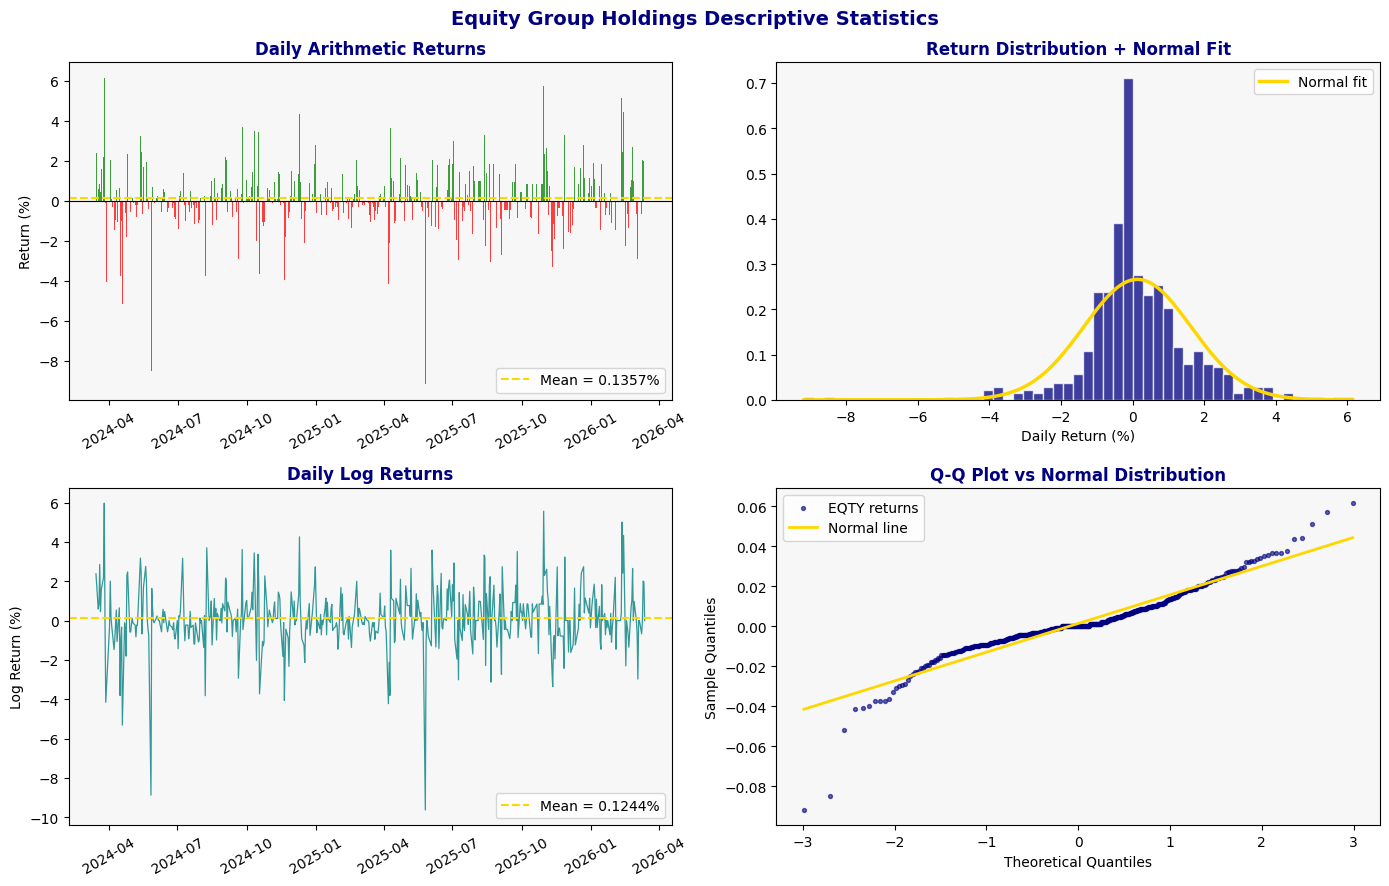

In [69]:

from scipy import stats

# Define colors
NAVY  = 'navy'
GOLD  = 'gold'
GREEN = 'green'
RED   = 'red'
TEAL  = 'teal'
LIGHT = '#f7f7f7'

#  VISUALISATION 
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Equity Group Holdings Descriptive Statistics', fontsize=14,
             fontweight='bold', color=NAVY)

# Returns time series (green = positive, red = negative)
colours = np.where(r_arith > 0, GREEN, RED)
axes[0,0].bar(returns['Date'], r_arith*100, color=colours, alpha=0.75, width=1)
axes[0,0].axhline(0, color='black', linewidth=0.8)
axes[0,0].axhline(r_arith.mean()*100, color=GOLD, linestyle='--', linewidth=1.5,
                   label=f'Mean = {r_arith.mean()*100:.4f}%')
axes[0,0].set_title('Daily Arithmetic Returns', fontweight='bold', color=NAVY)
axes[0,0].set_ylabel('Return (%)'); axes[0,0].legend(); axes[0,0].set_facecolor(LIGHT)
axes[0,0].tick_params(axis='x', rotation=30)

# Histogram + normal fit
axes[0,1].hist(r_arith*100, bins=55, color=NAVY, alpha=0.75, edgecolor='white', density=True)
x_fit = np.linspace(r_arith.min()*100, r_arith.max()*100, 300)
axes[0,1].plot(x_fit, stats.norm.pdf(x_fit, r_arith.mean()*100, r_arith.std()*100),
               color=GOLD, linewidth=2.5, label='Normal fit')
axes[0,1].set_title('Return Distribution + Normal Fit', fontweight='bold', color=NAVY)
axes[0,1].set_xlabel('Daily Return (%)'); axes[0,1].legend(); axes[0,1].set_facecolor(LIGHT)

# Log returns
axes[1,0].plot(returns['Date'], r_log*100, color=TEAL, linewidth=0.9, alpha=0.8)
axes[1,0].axhline(r_log.mean()*100, color=GOLD, linestyle='--', linewidth=1.5,
                   label=f'Mean = {r_log.mean()*100:.4f}%')
axes[1,0].set_title('Daily Log Returns', fontweight='bold', color=NAVY)
axes[1,0].set_ylabel('Log Return (%)'); axes[1,0].legend(); axes[1,0].set_facecolor(LIGHT)
axes[1,0].tick_params(axis='x', rotation=30)

# Q-Q Plot
(osm, osr), (slope, intercept, r2) = stats.probplot(r_arith, dist='norm')
axes[1,1].scatter(osm, osr, color=NAVY, s=8, alpha=0.6, label='EQTY returns')
axes[1,1].plot(osm, slope*np.array(osm)+intercept, color=GOLD, linewidth=2, label='Normal line')
axes[1,1].set_title('Q-Q Plot vs Normal Distribution', fontweight='bold', color=NAVY)
axes[1,1].set_xlabel('Theoretical Quantiles'); axes[1,1].set_ylabel('Sample Quantiles')
axes[1,1].legend(); axes[1,1].set_facecolor(LIGHT)

plt.tight_layout()
plt.show()


## 📐 Step 4 Annualised Return & Volatility

**Formulae:**
$$\mu_{annual} = \mu_{daily} \times N \qquad \sigma_{annual} = \sigma_{daily} \times \sqrt{N}$$

where $N = 252$ trading days/year (NSE standard).

**CAGR alternative:**
$$CAGR = \left(\frac{P_T}{P_0}\right)^{1/T} - 1$$


In [71]:
# CONSTANTS
N = 252  # trading days per year

#  DAILY RETURN STATS 
mu_daily, sigma_daily = r_arith.mean(), r_arith.std()

#  ANNUALISE 
EQTY_MU    = mu_daily * N
EQTY_SIGMA = sigma_daily * np.sqrt(N)
EQTY_VAR   = EQTY_SIGMA**2

# CAGR & HPR 
P0, PT = Equity_data['Close'].iloc[0], Equity_data['Close'].iloc[-1]
T_yrs   = (pd.to_datetime(Equity_data['Date'].iloc[-1]) - pd.to_datetime(Equity_data['Date'].iloc[0])).days / 365.25
CAGR    = (PT / P0)**(1 / T_yrs) - 1
HPR     = (PT - P0) / P0

#  RESULTS 
print(f"Annualized Return: {EQTY_MU*100:.4f}% | CAGR: {CAGR*100:.4f}% | Total HPR: {HPR*100:.4f}%")
print(f"Annualized Volatility: {EQTY_SIGMA*100:.4f}% | Annual Variance: {EQTY_VAR:.6f}")

results_4 = pd.DataFrame({
    'Metric': ['μ_daily','μ_annual','CAGR','Total HPR',
               'σ_daily','σ_annual','σ² annual'],
    'Value':  [f'{mu_daily*100:.4f}%', f'{EQTY_MU*100:.4f}%', f'{CAGR*100:.4f}%',
               f'{HPR*100:.4f}%', f'{sigma_daily*100:.4f}%', f'{EQTY_SIGMA*100:.4f}%',
               f'{EQTY_VAR:.6f}']
})
display(results_4.set_index('Metric'))

Annualized Return: 34.2040% | CAGR: nan% | Total HPR: nan%
Annualized Volatility: 23.7947% | Annual Variance: 0.056619


,Value
Metric,
μ_daily,0.1357%
μ_annual,34.2040%
CAGR,nan%
Total HPR,nan%
σ_daily,1.4989%
σ_annual,23.7947%
σ² annual,0.056619


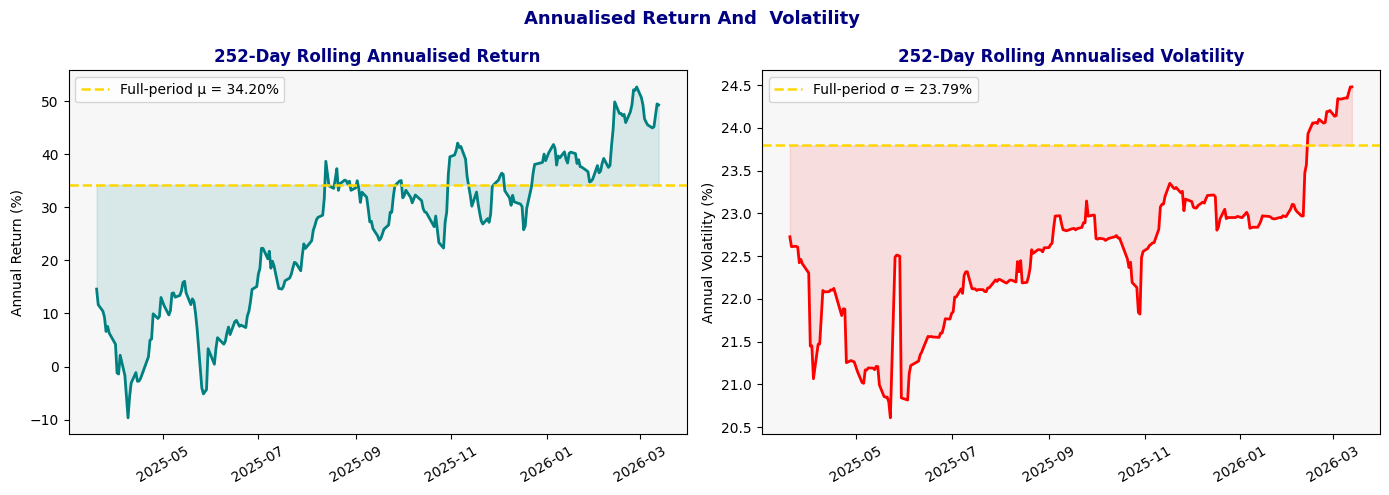

In [74]:
#  ROLLING RETURN & VOLATILITY 
returns['Roll_Return'] = returns['Return_Arith'].rolling(252).mean() * 252
returns['Roll_Vol']    = returns['Return_Arith'].rolling(252).std()  * np.sqrt(252)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Annualised Return And  Volatility ', fontsize=13,
             fontweight='bold', color='navy')

r_plot = returns.dropna(subset=['Roll_Return','Roll_Vol'])

# Rolling Annualised Return
axes[0].plot(r_plot['Date'], r_plot['Roll_Return']*100, color='teal', linewidth=2)
axes[0].axhline(EQTY_MU*100, color='gold', linestyle='--', linewidth=1.8,
                label=f'Full-period μ = {EQTY_MU*100:.2f}%')
axes[0].fill_between(r_plot['Date'], r_plot['Roll_Return']*100, EQTY_MU*100, alpha=0.12, color='teal')
axes[0].set_title('252-Day Rolling Annualised Return', fontweight='bold', color='navy')
axes[0].set_ylabel('Annual Return (%)')
axes[0].legend()
axes[0].set_facecolor('#f7f7f7')
axes[0].tick_params(axis='x', rotation=30)

# Rolling Annualised Volatility
axes[1].plot(r_plot['Date'], r_plot['Roll_Vol']*100, color='red', linewidth=2)
axes[1].axhline(EQTY_SIGMA*100, color='gold', linestyle='--', linewidth=1.8,
                label=f'Full-period σ = {EQTY_SIGMA*100:.2f}%')
axes[1].fill_between(r_plot['Date'], r_plot['Roll_Vol']*100, EQTY_SIGMA*100, alpha=0.10, color='red')
axes[1].set_title('252-Day Rolling Annualised Volatility', fontweight='bold', color='navy')
axes[1].set_ylabel('Annual Volatility (%)')
axes[1].legend()
axes[1].set_facecolor('#f7f7f7')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


## 🔢 Step 5 — Variance-Covariance Matrix

**Formula:**
$$\text{Cov}(i,j) = \rho_{ij} \times \sigma_i \times \sigma_j$$

On the diagonal: $\text{Cov}(i,i) = \sigma_i^2$ (variance).  
Matrix form: $\Sigma = D\rho D$ where $D = \text{diag}(\sigma_1, \sigma_2, \sigma_3)$.

**Asset universe:** EQTY (risky equity) + KGB 10yr Bond + 91-day T-Bill


In [75]:
#  ASSET PARAMETERS 
ASSETS = ['EQTY', 'KGB Bond (10yr)', 'T-Bill (91-day)']

# Standard deviations (annualised)
SIGMA_EQTY  = EQTY_SIGMA   # from Step 4 (real data)
SIGMA_BOND  = 0.04000       # assumed: stable sovereign bond
SIGMA_TBILL = 0.00000       # riskless asset: σ = 0 by definition

sigmas = np.array([SIGMA_EQTY, SIGMA_BOND, SIGMA_TBILL])

# Expected returns (annualised)
MU_EQTY  = EQTY_MU    # from Step 4
MU_BOND  = 0.1450     # Kenya 10yr government bond yield (CBK)
MU_TBILL = 0.1350     # CBK 91-day T-bill rate, Feb 2026

#  CORRELATION MATRIX 
# ρ(EQTY, Bond)  = 0.25 → low positive (both sensitive to Kenya macro/forex)
# ρ(EQTY, TBill) = 0.00 → zero (T-bill is riskless)
# ρ(Bond, TBill) = 0.10 → slight positive (both fixed income)

RHO_EB = 0.25   # EQTY–Bond
RHO_ET = 0.00   # EQTY–T-Bill
RHO_BT = 0.10   # Bond–T-Bill

corr_matrix = np.array([
    [1.00,   RHO_EB, RHO_ET],
    [RHO_EB, 1.00,   RHO_BT],
    [RHO_ET, RHO_BT, 1.00  ]
])

# COVARIANCE MATRIX 
# Σ = D × ρ × D   where D = diag(σ_1, σ_2, σ_3)
D          = np.diag(sigmas)
cov_matrix = D @ corr_matrix @ D

# DISPLAY 
print("CORRELATION MATRIX (ρ):")
corr_df = pd.DataFrame(corr_matrix, index=ASSETS, columns=ASSETS)
display(corr_df.round(4))

print("\nVARIANCE-COVARIANCE MATRIX (Σ):")
cov_df = pd.DataFrame(cov_matrix, index=ASSETS, columns=ASSETS)
display(cov_df.round(6))

print("\nCell-by-cell workings:")
short = ['EQTY','Bond','TBill']
for i in range(3):
    for j in range(3):
        tag = '  ← VARIANCE' if i==j else ''
        print(f"  Cov({short[i]},{short[j]}) = {corr_matrix[i,j]:.2f} × {sigmas[i]:.5f} × {sigmas[j]:.5f} = {cov_matrix[i,j]:.6f}{tag}")


CORRELATION MATRIX (ρ):


,EQTY,KGB Bond (10yr),T-Bill (91-day)
EQTY,1.00,0.25,0.0
KGB Bond (10yr),0.25,1.00,0.1
T-Bill (91-day),0.00,0.10,1.0



VARIANCE-COVARIANCE MATRIX (Σ):


,EQTY,KGB Bond (10yr),T-Bill (91-day)
EQTY,0.056619,0.002379,0.0
KGB Bond (10yr),0.002379,0.001600,0.0
T-Bill (91-day),0.000000,0.000000,0.0



Cell-by-cell workings:
  Cov(EQTY,EQTY) = 1.00 × 0.23795 × 0.23795 = 0.056619  ← VARIANCE
  Cov(EQTY,Bond) = 0.25 × 0.23795 × 0.04000 = 0.002379
  Cov(EQTY,TBill) = 0.00 × 0.23795 × 0.00000 = 0.000000
  Cov(Bond,EQTY) = 0.25 × 0.04000 × 0.23795 = 0.002379
  Cov(Bond,Bond) = 1.00 × 0.04000 × 0.04000 = 0.001600  ← VARIANCE
  Cov(Bond,TBill) = 0.10 × 0.04000 × 0.00000 = 0.000000
  Cov(TBill,EQTY) = 0.00 × 0.00000 × 0.23795 = 0.000000
  Cov(TBill,Bond) = 0.10 × 0.00000 × 0.04000 = 0.000000
  Cov(TBill,TBill) = 1.00 × 0.00000 × 0.00000 = 0.000000  ← VARIANCE


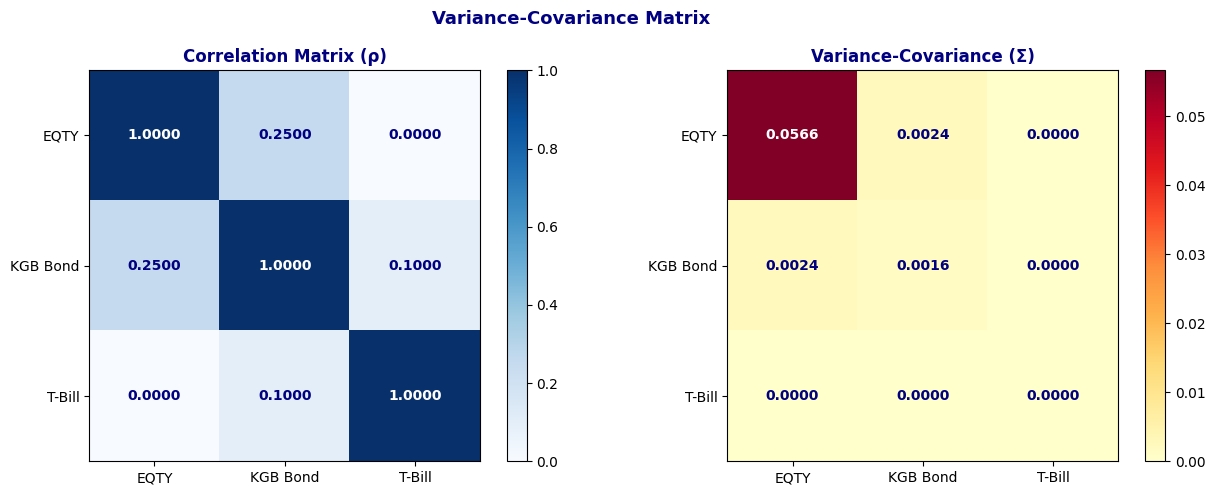

In [77]:
#  HEATMAP VISUALISATION 
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Variance-Covariance Matrix ', fontsize=13,
             fontweight='bold', color=NAVY)
short_labels = ['EQTY','KGB Bond','T-Bill']

for ax, mat, title, cmap in [
    (axes[0], corr_matrix, 'Correlation Matrix (ρ)', 'Blues'),
    (axes[1], cov_matrix,  'Variance-Covariance (Σ)', 'YlOrRd')
]:
    im = ax.imshow(mat, cmap=cmap, vmin=0)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(short_labels, fontsize=10)
    ax.set_yticklabels(short_labels, fontsize=10)
    ax.set_title(title, fontweight='bold', color=NAVY)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{mat[i,j]:.4f}', ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if mat[i,j] > mat.max()*0.6 else NAVY)
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()


## 📉 Step 6 — CAPM: Expected Return

**CAPM Formula:**
$$E(r) = R_f + \beta \times (R_m - R_f)$$

| Input | Value | Source |
|-------|-------|--------|
| $R_f$ | 13.50% | CBK Kenya 91-day T-bill, Feb 2026 |
| $\beta$ | 0.92 | Genghis Capital / SIB NSE Research |
| $R_m$ | 18.00% | NSE20 index return, CMA Kenya 2024-25 |

**Jensen's Alpha:** $\alpha = \mu_{observed} - E(r)_{CAPM}$


In [78]:
#  INPUTS
RF   = 0.1350   # CBK 91-day T-bill rate, Feb 2026
BETA = 0.92     # EQTY beta vs NSE20 (Genghis Capital / SIB)
RM   = 0.1800   # NSE20 annual return (CMA Kenya 2024-25)

# STEP-BY-STEP CAPM CALCULATION 
MRP          = RM - RF                 # Market Risk Premium
beta_x_mrp   = BETA * MRP             # Systematic risk premium
CAPM_ER      = RF + beta_x_mrp        # CAPM Expected Return
ALPHA        = EQTY_MU - CAPM_ER      # Jensen's Alpha

print("CAPM:  E(r) = Rf + β × (Rm − Rf)")
print()
print(f"  Step 1: Market Risk Premium = Rm − Rf = {RM*100:.2f}% − {RF*100:.2f}% = {MRP*100:.2f}%")
print(f"  Step 2: β × MRP             = {BETA} × {MRP*100:.2f}% = {beta_x_mrp*100:.4f}%")
print(f"  Step 3: E(r) = Rf + β×MRP   = {RF*100:.2f}% + {beta_x_mrp*100:.4f}%")
print()
print(f"  ╔══════════════════════════════════════════╗")
print(f"  ║  CAPM E(r)      = {CAPM_ER*100:.4f}%             ║")
print(f"  ║  Observed μ     = {EQTY_MU*100:.4f}%             ║")
print(f"  ║  Jensen's Alpha = +{ALPHA*100:.4f}%            ║")
print(f"  ╚══════════════════════════════════════════╝")
print()
print(f"  Interpretation: Positive α ({ALPHA*100:.2f}pp) → EQTY outperforms CAPM prediction.")
print(f"  Driven by digital banking growth and pan-African expansion (7 countries).")

capm_df = pd.DataFrame({
    'Component': ['Rf (T-bill)', 'β (EQTY beta)', 'Rm (NSE20)',
                  'MRP = Rm−Rf', 'β × MRP', 'CAPM E(r)', "Obs. μ", "Jensen's α"],
    'Value': [f'{RF*100:.2f}%', f'{BETA}', f'{RM*100:.2f}%',
              f'{MRP*100:.2f}%', f'{beta_x_mrp*100:.4f}%',
              f'{CAPM_ER*100:.4f}%', f'{EQTY_MU*100:.4f}%', f'+{ALPHA*100:.4f}%']
})
display(capm_df.set_index('Component'))


CAPM:  E(r) = Rf + β × (Rm − Rf)

  Step 1: Market Risk Premium = Rm − Rf = 18.00% − 13.50% = 4.50%
  Step 2: β × MRP             = 0.92 × 4.50% = 4.1400%
  Step 3: E(r) = Rf + β×MRP   = 13.50% + 4.1400%

  ╔══════════════════════════════════════════╗
  ║  CAPM E(r)      = 17.6400%             ║
  ║  Observed μ     = 34.2040%             ║
  ║  Jensen's Alpha = +16.5640%            ║
  ╚══════════════════════════════════════════╝

  Interpretation: Positive α (16.56pp) → EQTY outperforms CAPM prediction.
  Driven by digital banking growth and pan-African expansion (7 countries).


,Value
Component,
Rf (T-bill),13.50%
β (EQTY beta),0.92
Rm (NSE20),18.00%
MRP = Rm−Rf,4.50%
β × MRP,4.1400%
CAPM E(r),17.6400%
Obs. μ,34.2040%
Jensen's α,+16.5640%


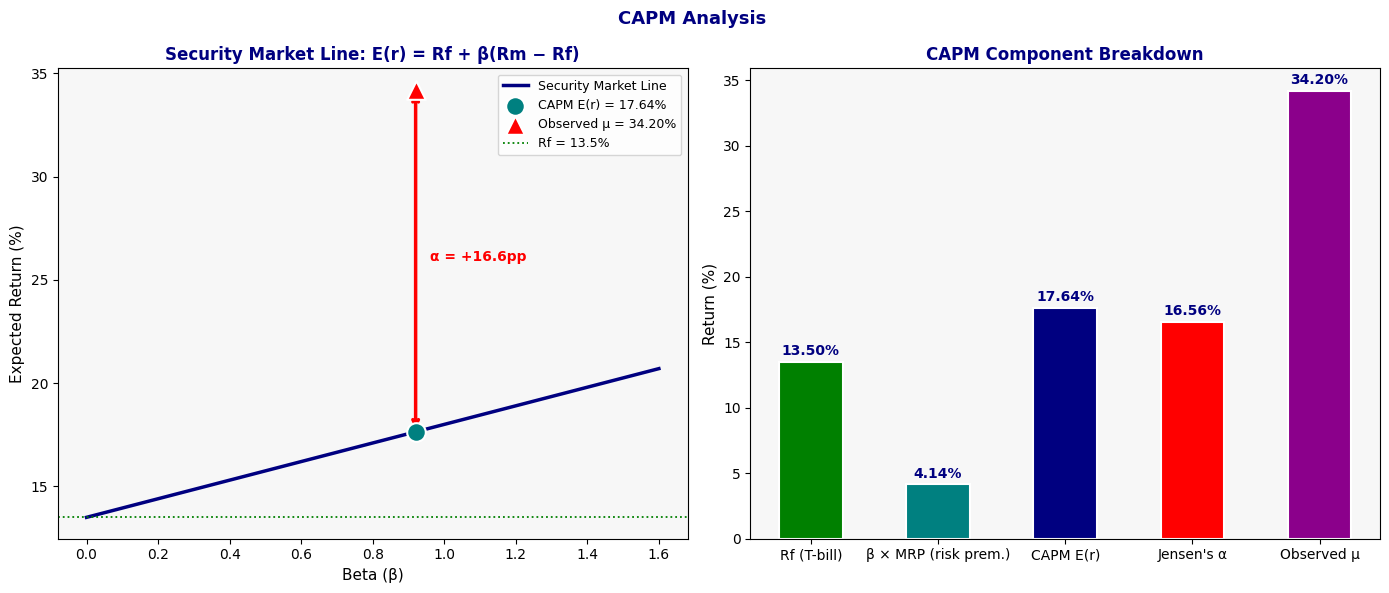

In [81]:
# CAPM VISUALISATION 
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('CAPM Analysis ', fontsize=13, fontweight='bold', color='navy')

# Left: Security Market Line
ax = axes[0]
ax.set_facecolor('#f7f7f7')  # LIGHT background
beta_range = np.linspace(0, 1.6, 200)
sml_vals   = (RF + beta_range * MRP) * 100
ax.plot(beta_range, sml_vals, color='navy', linewidth=2.5, label='Security Market Line')

# CAPM expected return point
ax.scatter([BETA], [CAPM_ER*100], color='teal', s=180, zorder=7,
           label=f'CAPM E(r) = {CAPM_ER*100:.2f}%', edgecolors='white', linewidth=1.5)

# Observed equity return
ax.scatter([BETA], [EQTY_MU*100], color='red', s=180, zorder=7, marker='^',
           label=f'Observed μ = {EQTY_MU*100:.2f}%', edgecolors='white', linewidth=1.5)

# Alpha arrow
ax.annotate('', xy=(BETA, EQTY_MU*100), xytext=(BETA, CAPM_ER*100),
            arrowprops=dict(arrowstyle='<->', color='red', lw=2.5))
ax.text(BETA+0.04, (CAPM_ER+EQTY_MU)/2*100, f'α = +{ALPHA*100:.1f}pp',
        fontsize=10, color='red', fontweight='bold')

ax.axhline(RF*100, color='green', linestyle=':', linewidth=1.3, label=f'Rf = {RF*100:.1f}%')

ax.set_xlabel('Beta (β)', fontsize=11)
ax.set_ylabel('Expected Return (%)', fontsize=11)
ax.set_title('Security Market Line: E(r) = Rf + β(Rm − Rf)', fontweight='bold', color='navy')
ax.legend(fontsize=9)

# Right: Component bar chart
ax2 = axes[1]
ax2.set_facecolor('#f7f7f7')  # LIGHT background
comps  = ['Rf (T-bill)', 'β × MRP (risk prem.)', 'CAPM E(r)', "Jensen's α", 'Observed μ']
vals_b = [RF*100, beta_x_mrp*100, CAPM_ER*100, ALPHA*100, EQTY_MU*100]
bcols  = ['green', 'teal', 'navy', 'red', '#8B008B']

bars = ax2.bar(comps, vals_b, color=bcols, width=0.5, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, vals_b):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{val:.2f}%',
             ha='center', va='bottom', fontsize=10, fontweight='bold', color='navy')

ax2.set_ylabel('Return (%)', fontsize=11)
ax2.set_title('CAPM Component Breakdown', fontweight='bold', color='navy')

plt.tight_layout()
plt.show()

## 🗂️ Step 7 Portfolio Return & Variance (3-Asset)

**Weights: 60% EQTY | 25% KGB Bond | 15% T-Bill**

**Portfolio Return:**
$$E(r_p) = \sum_i w_i \cdot E(r_i) = w_E r_E + w_B r_B + w_T r_T$$

**Portfolio Variance (9-term expansion):**
$$\sigma^2_p = \mathbf{w}^\top \Sigma \mathbf{w} = \sum_i\sum_j w_i w_j \text{Cov}(i,j)$$


In [82]:
# WEIGHTS & EXPECTED RETURNS 
W  = np.array([0.60, 0.25, 0.15])             # weights
mu = np.array([MU_EQTY, MU_BOND, MU_TBILL])   # expected returns

#  PORTFOLIO EXPECTED RETURN 
PORT_R = np.dot(W, mu)

print("PORTFOLIO EXPECTED RETURN:  E(r_p) = Σ w_i × E(r_i)")
print()
contribs = [W[i]*mu[i] for i in range(3)]
for i, (a, wi, mi, ci) in enumerate(zip(ASSETS, W, mu, contribs)):
    print(f"  {a:<18}: {wi:.2f} × {mi*100:.4f}% = {ci*100:.4f}%")
print(f"  {'─'*48}")
print(f"  E(r_p) = {PORT_R*100:.4f}%")

#  PORTFOLIO VARIANCE (all 9 terms) 
print("\nPORTFOLIO VARIANCE:  σ²_p = Σ_i Σ_j w_i × w_j × Cov(i,j)")
print()
short3 = ['EQTY','Bond','TBill']
terms = []
for i in range(3):
    for j in range(3):
        term = W[i] * W[j] * cov_matrix[i,j]
        terms.append(term)
        tag = '  ← VARIANCE' if i==j else ''
        print(f"  w_{short3[i]}×w_{short3[j]}×Cov = {W[i]:.2f}×{W[j]:.2f}×{cov_matrix[i,j]:.6f} = {term:.8f}{tag}")

PORT_VAR = sum(terms)
PORT_S   = np.sqrt(PORT_VAR)

print(f"\n  σ²_p = {PORT_VAR:.8f}")
print(f"  σ_p  = √{PORT_VAR:.8f} = {PORT_S*100:.4f}%")

# Verify with matrix algebra
check = float(W @ cov_matrix @ W)
print(f"\n  Matrix verification (w^T Σ w) = {check:.8f}  Match: {np.isclose(PORT_VAR, check)}")


PORTFOLIO EXPECTED RETURN:  E(r_p) = Σ w_i × E(r_i)

  EQTY              : 0.60 × 34.2040% = 20.5224%
  KGB Bond (10yr)   : 0.25 × 14.5000% = 3.6250%
  T-Bill (91-day)   : 0.15 × 13.5000% = 2.0250%
  ────────────────────────────────────────────────
  E(r_p) = 26.1724%

PORTFOLIO VARIANCE:  σ²_p = Σ_i Σ_j w_i × w_j × Cov(i,j)

  w_EQTY×w_EQTY×Cov = 0.60×0.60×0.056619 = 0.02038280  ← VARIANCE
  w_EQTY×w_Bond×Cov = 0.60×0.25×0.002379 = 0.00035692
  w_EQTY×w_TBill×Cov = 0.60×0.15×0.000000 = 0.00000000
  w_Bond×w_EQTY×Cov = 0.25×0.60×0.002379 = 0.00035692
  w_Bond×w_Bond×Cov = 0.25×0.25×0.001600 = 0.00010000  ← VARIANCE
  w_Bond×w_TBill×Cov = 0.25×0.15×0.000000 = 0.00000000
  w_TBill×w_EQTY×Cov = 0.15×0.60×0.000000 = 0.00000000
  w_TBill×w_Bond×Cov = 0.15×0.25×0.000000 = 0.00000000
  w_TBill×w_TBill×Cov = 0.15×0.15×0.000000 = 0.00000000  ← VARIANCE

  σ²_p = 0.02119665
  σ_p  = √0.02119665 = 14.5591%

  Matrix verification (w^T Σ w) = 0.02119665  Match: True


,Weight,Ret. Contrib,Var. Contrib
Asset,,,
EQTY,60%,20.5224%,0.020740
KGB Bond (10yr),25%,3.6250%,0.000457
T-Bill (91-day),15%,2.0250%,0.000000



  ➤  Portfolio E(r_p) = 26.1724%
  ➤  Portfolio σ_p    = 14.5591%
  ➤  Portfolio σ²_p   = 0.021197


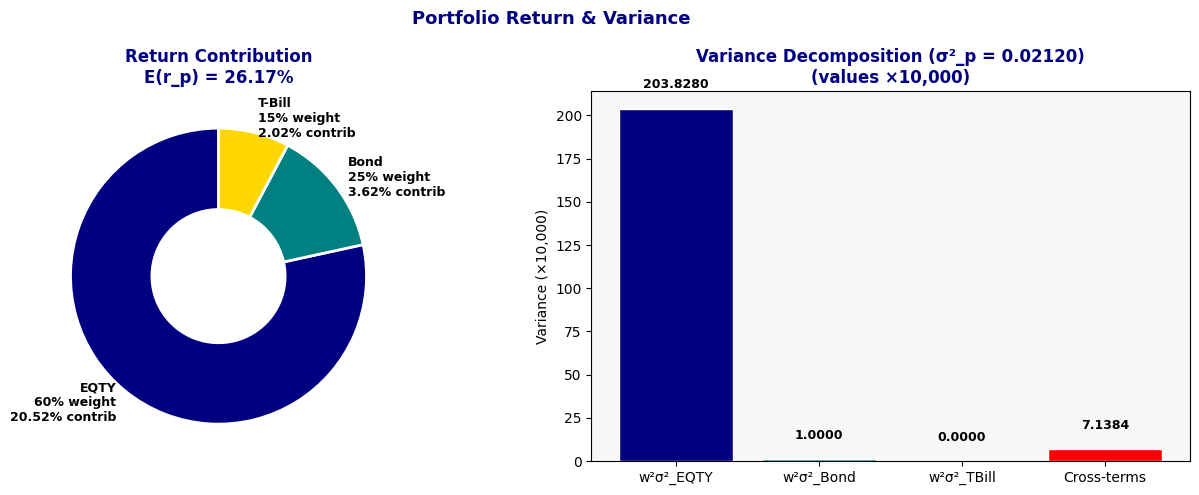

In [84]:
# CONTRIBUTION TABLE 
contrib_df = pd.DataFrame({
    'Asset'          : ASSETS,
    'Weight'         : [f'{w*100:.0f}%' for w in W],
    'Ret. Contrib'   : [f'{W[i]*mu[i]*100:.4f}%' for i in range(3)],
    'Var. Contrib'   : [f'{sum(W[i]*W[j]*cov_matrix[i,j] for j in range(3)):.6f}' for i in range(3)]
})
display(contrib_df.set_index('Asset'))

print(f"\n  ➤  Portfolio E(r_p) = {PORT_R*100:.4f}%")
print(f"  ➤  Portfolio σ_p    = {PORT_S*100:.4f}%")
print(f"  ➤  Portfolio σ²_p   = {PORT_VAR:.6f}")

# PIE CHART
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Portfolio Return & Variance ', fontsize=13, fontweight='bold', color=NAVY)

# Return contribution donut
labels_pie = [f'{a}\n{W[i]*100:.0f}% weight\n{contribs[i]*100:.2f}% contrib' for i, a in enumerate(['EQTY','Bond','T-Bill'])]
wedge_props = dict(width=0.55, edgecolor='white', linewidth=2)
axes[0].pie([c*100 for c in contribs], labels=labels_pie,
            colors=[NAVY,TEAL,GOLD], wedgeprops=wedge_props,
            startangle=90, textprops={'fontsize':9,'fontweight':'bold'})
axes[0].set_title(f'Return Contribution\nE(r_p) = {PORT_R*100:.2f}%', fontweight='bold', color=NAVY)

# Variance decomposition
axes[1].set_facecolor(LIGHT)
var_diag  = [W[i]**2 * cov_matrix[i,i] for i in range(3)]
var_cross = PORT_VAR - sum(var_diag)
v_labels  = ['w²σ²_EQTY', 'w²σ²_Bond', 'w²σ²_TBill', 'Cross-terms']
v_vals    = var_diag + [var_cross]
v_cols    = [NAVY, TEAL, GOLD, RED]
bars = axes[1].bar(v_labels, [v*10000 for v in v_vals], color=v_cols, edgecolor='white')
for bar, val in zip(bars, v_vals):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001*10000,
                 f'{val*10000:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[1].set_title(f'Variance Decomposition (σ²_p = {PORT_VAR:.5f})\n(values ×10,000)',
                  fontweight='bold', color=NAVY)
axes[1].set_ylabel('Variance (×10,000)')

plt.tight_layout()
plt.show()



## 🏆 Step 8 Performance Ratios

| Ratio | Formula | Measures |
|-------|---------|---------|
| **Sharpe** | $(E(r_p) - R_f) / \sigma_p$ | Excess return per unit of **total** risk |
| **Treynor** | $(E(r_p) - R_f) / \beta_p$ | Excess return per unit of **systematic** risk |
| **Information Ratio** | $\alpha / TE$ | Active return per unit of **active** risk |


In [85]:
#  PORTFOLIO BETA 
BETA_BOND  = 0.10   # low systematic risk (sovereign bond)
BETA_TBILL = 0.00   # riskless
PORT_BETA  = W[0]*BETA + W[1]*BETA_BOND + W[2]*BETA_TBILL

#  BENCHMARK & ACTIVE RETURN 
BENCH_R    = W[0]*RM + W[1]*MU_BOND + W[2]*MU_TBILL
ACTIVE_R   = PORT_R - BENCH_R
TRACKING_E = 0.04   # assumed 4% tracking error

#  SHARPE RATIO 
SHARPE  = (PORT_R - RF) / PORT_S

print("① SHARPE RATIO")
print(f"   S = (E(r_p) − Rf) / σ_p = ({PORT_R*100:.4f}% − {RF*100:.2f}%) / {PORT_S*100:.4f}%")
print(f"   ➤  Sharpe = {SHARPE:.4f}  [{PORT_R*100:.2f}−{RF*100:.2f}={((PORT_R-RF)*100):.2f} excess, ÷ {PORT_S*100:.2f} risk]")

#  TREYNOR RATIO
TREYNOR = (PORT_R - RF) / PORT_BETA

print("\n② TREYNOR RATIO")
print(f"   β_p = {W[0]}×{BETA} + {W[1]}×{BETA_BOND} + {W[2]}×{BETA_TBILL} = {PORT_BETA:.4f}")
print(f"   T = (E(r_p) − Rf) / β_p = {(PORT_R-RF)*100:.4f}% / {PORT_BETA:.4f}")
print(f"   ➤  Treynor = {TREYNOR*100:.4f}%")

# INFORMATION RATIO
IR = ACTIVE_R / TRACKING_E

print("\n③ INFORMATION RATIO")
print(f"   Benchmark  = {W[0]}×{RM*100:.2f}% + {W[1]}×{MU_BOND*100:.2f}% + {W[2]}×{MU_TBILL*100:.2f}% = {BENCH_R*100:.4f}%")
print(f"   Active Ret = {PORT_R*100:.4f}% − {BENCH_R*100:.4f}% = {ACTIVE_R*100:.4f}%")
print(f"   Track. Err = {TRACKING_E*100:.1f}%  (assumed)")
print(f"   ➤  IR = {ACTIVE_R*100:.4f}% / {TRACKING_E*100:.1f}% = {IR:.4f}")

#  SUMMARY TABLE 
ratios_df = pd.DataFrame({
    'Metric': ['E(r_p)', 'σ_p', 'β_p', 'Rf', 'Benchmark', 'Active Return',
               'Sharpe Ratio', 'Treynor Ratio', 'Information Ratio', "Jensen's Alpha"],
    'Value':  [f'{PORT_R*100:.4f}%', f'{PORT_S*100:.4f}%', f'{PORT_BETA:.4f}',
               f'{RF*100:.2f}%', f'{BENCH_R*100:.4f}%', f'{ACTIVE_R*100:.4f}%',
               f'{SHARPE:.4f}', f'{TREYNOR*100:.4f}%', f'{IR:.4f}', f'+{ALPHA*100:.4f}%'],
    'Interpretation': [
        'Mandate: ≥20% ✓', 'Mandate: ≤20% ✓', 'Low systematic risk',
        'CBK T-bill Feb 2026', 'Blended benchmark', 'Portfolio beats benchmark',
        '>0.80 ✓ (mandate)', 'High (low β helps)', '>2.0 = exceptional ✓', 'Positive = outperforms CAPM'
    ]
})
display(ratios_df.set_index('Metric'))


① SHARPE RATIO
   S = (E(r_p) − Rf) / σ_p = (26.1724% − 13.50%) / 14.5591%
   ➤  Sharpe = 0.8704  [26.17−13.50=12.67 excess, ÷ 14.56 risk]

② TREYNOR RATIO
   β_p = 0.6×0.92 + 0.25×0.1 + 0.15×0.0 = 0.5770
   T = (E(r_p) − Rf) / β_p = 12.6724% / 0.5770
   ➤  Treynor = 21.9626%

③ INFORMATION RATIO
   Benchmark  = 0.6×18.00% + 0.25×14.50% + 0.15×13.50% = 16.4500%
   Active Ret = 26.1724% − 16.4500% = 9.7224%
   Track. Err = 4.0%  (assumed)
   ➤  IR = 9.7224% / 4.0% = 2.4306


,Value,Interpretation
Metric,,
E(r_p),26.1724%,Mandate: ≥20% ✓
σ_p,14.5591%,Mandate: ≤20% ✓
β_p,0.5770,Low systematic risk
Rf,13.50%,CBK T-bill Feb 2026
Benchmark,16.4500%,Blended benchmark
Active Return,9.7224%,Portfolio beats benchmark
Sharpe Ratio,0.8704,>0.80 ✓ (mandate)
Treynor Ratio,21.9626%,High (low β helps)
Information Ratio,2.4306,>2.0 = exceptional ✓


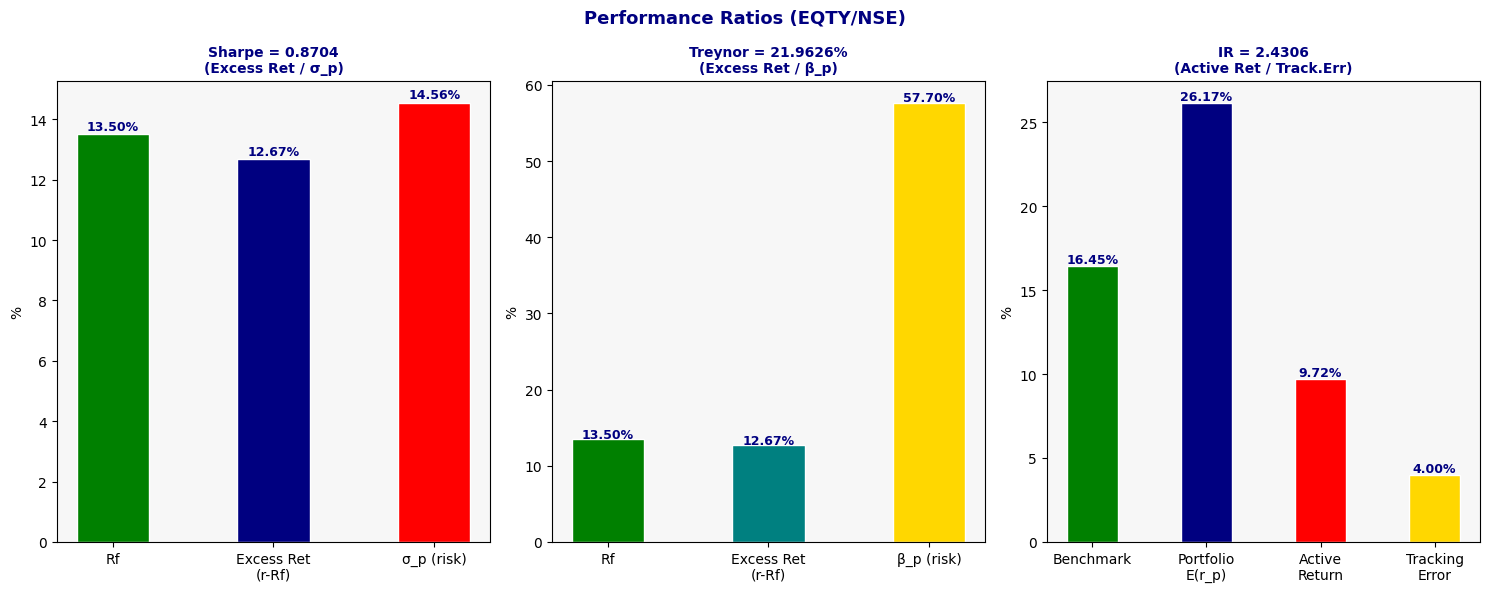

In [86]:
#  VISUALISATION 
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
fig.suptitle('Performance Ratios (EQTY/NSE)', fontsize=13,
             fontweight='bold', color=NAVY)

for ax, title, cats, vals, cols in [
    (axes[0], f'Sharpe = {SHARPE:.4f}\n(Excess Ret / σ_p)',
     ['Rf', 'Excess Ret\n(r-Rf)', 'σ_p (risk)'],
     [RF*100, (PORT_R-RF)*100, PORT_S*100],
     [GREEN, NAVY, RED]),
    (axes[1], f'Treynor = {TREYNOR*100:.4f}%\n(Excess Ret / β_p)',
     ['Rf', 'Excess Ret\n(r-Rf)', 'β_p (risk)'],
     [RF*100, (PORT_R-RF)*100, PORT_BETA*100],
     [GREEN, TEAL, GOLD]),
    (axes[2], f'IR = {IR:.4f}\n(Active Ret / Track.Err)',
     ['Benchmark', 'Portfolio\nE(r_p)', 'Active\nReturn', 'Tracking\nError'],
     [BENCH_R*100, PORT_R*100, ACTIVE_R*100, TRACKING_E*100],
     [GREEN, NAVY, RED, GOLD])
]:
    ax.set_facecolor(LIGHT)
    bars = ax.bar(cats, vals, color=cols[:len(cats)], width=0.45, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.15,
                f'{val:.2f}%', ha='center', fontsize=9, fontweight='bold', color=NAVY)
    ax.set_title(title, fontweight='bold', color=NAVY, fontsize=10)
    ax.set_ylabel('%')

plt.tight_layout()
plt.show()



## 🎯 Step 9 Efficient Frontier

**Part A – 2-Asset (EQTY + Bond):**
$$\sigma^2_p = w^2\sigma^2_E + (1-w)^2\sigma^2_B + 2w(1-w)\text{Cov}(E,B)$$

**Part B – 3-Asset SciPy optimisation:**  
For each target return $r^*$, minimise $\mathbf{w}^\top \Sigma \mathbf{w}$  
subject to $\sum w_i = 1$, $0 \le w_i \le 1$, $w_{EQTY} \le 0.65$ (mandate cap).


In [87]:
#  PART A: 2-ASSET EFFICIENT FRONTIER 
print("PART A — 2-Asset Efficient Frontier (EQTY + KGB Bond)")
print()

weights_2a = np.linspace(0, 1, 21)
ef2_r, ef2_s, ef2_sh = [], [], []

print(f"  {'w_EQTY':>8} {'w_Bond':>8} {'E(r_p)':>10} {'σ_p':>10} {'Sharpe':>10}")
print(f"  {'─'*52}")

for w in weights_2a:
    r_p = w*MU_EQTY + (1-w)*MU_BOND
    v_p = w**2*SIGMA_EQTY**2 + (1-w)**2*SIGMA_BOND**2 + 2*w*(1-w)*cov_matrix[0,1]
    s_p = np.sqrt(v_p)
    sh  = (r_p - RF)/s_p if s_p > 0 else 0
    ef2_r.append(r_p); ef2_s.append(s_p); ef2_sh.append(sh)
    marker = "  ◄ Mandate target" if abs(w-0.60)<0.001 else ""
    print(f"  {w:>8.2f} {1-w:>8.2f} {r_p*100:>9.4f}% {s_p*100:>9.4f}% {sh:>10.4f}{marker}")

print(f"\n  Min Variance: w_EQTY={weights_2a[np.argmin(ef2_s)]:.2f}, σ={min(ef2_s)*100:.4f}%")
print(f"  Max Sharpe  : w_EQTY={weights_2a[np.argmax(ef2_sh)]:.2f}, Sharpe={max(ef2_sh):.4f}")


PART A — 2-Asset Efficient Frontier (EQTY + KGB Bond)

    w_EQTY   w_Bond     E(r_p)        σ_p     Sharpe
  ────────────────────────────────────────────────────
      0.00     1.00   14.5000%    4.0000%     0.2500
      0.05     0.95   15.4852%    4.2563%     0.4664
      0.10     0.90   16.4704%    4.7859%     0.6207
      0.15     0.85   17.4556%    5.5106%     0.7178
      0.20     0.80   18.4408%    6.3641%     0.7764
      0.25     0.75   19.4260%    7.3014%     0.8116
      0.30     0.70   20.4112%    8.2940%     0.8333
      0.35     0.65   21.3964%    9.3244%     0.8469
      0.40     0.60   22.3816%   10.3813%     0.8555
      0.45     0.55   23.3668%   11.4574%     0.8612
      0.50     0.50   24.3520%   12.5477%     0.8649
      0.55     0.45   25.3372%   13.6488%     0.8673
      0.60     0.40   26.3224%   14.7584%     0.8688  ◄ Mandate target
      0.65     0.35   27.3076%   15.8746%     0.8698
      0.70     0.30   28.2928%   16.9961%     0.8704
      0.75     0.25   29

In [88]:
# PART B: 3-ASSET EFFICIENT FRONTIER 
print("PART B — 3-Asset Efficient Frontier (SciPy)")
print()

mu_vec  = np.array([MU_EQTY, MU_BOND, MU_TBILL])
bounds  = [(0, 0.65), (0, 1), (0, 1)]
x0      = [1/3, 1/3, 1/3]

def pret(w): return float(np.dot(w, mu_vec))
def pvol(w): return float(np.sqrt(w @ cov_matrix @ w))
def pvar(w): return float(w @ cov_matrix @ w)

target_rets = np.linspace(MU_TBILL, MU_EQTY*0.90, 60)
ef3_r, ef3_s = [], []

for target in target_rets:
    cons = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        {'type': 'eq', 'fun': lambda w, t=target: pret(w) - t}
    ]
    res = minimize(pvar, x0, method='SLSQP', bounds=bounds, constraints=cons,
                   options={'ftol':1e-12,'maxiter':1000})
    if res.success and abs(pret(res.x)-target) < 1e-4:
        ef3_r.append(pret(res.x)*100)
        ef3_s.append(pvol(res.x)*100)

print(f"  Converged: {len(ef3_r)}/60 points")
print(f"  E(r) range : {min(ef3_r):.2f}% – {max(ef3_r):.2f}%")
print(f"  σ range    : {min(ef3_s):.2f}% – {max(ef3_s):.2f}%")

# Key optimised portfolios
def neg_sharpe(w): return -(pret(w)-RF)/pvol(w) if pvol(w)>0 else 0
cons_sum = [{'type':'eq','fun':lambda w: np.sum(w)-1}]
w_min = minimize(pvar, x0, method='SLSQP', bounds=bounds, constraints=cons_sum).x
w_tan = minimize(neg_sharpe, x0, method='SLSQP', bounds=bounds, constraints=cons_sum).x
w_opt = np.array([0.60, 0.25, 0.15])

print("\nKey Portfolios:")
for label, w in [("Min Variance", w_min), ("Max Sharpe (Tangency)", w_tan), ("Mandate Optimal 60/25/15", w_opt)]:
    r, s, sh = pret(w), pvol(w), (pret(w)-RF)/pvol(w) if pvol(w)>0 else 0
    wt = ", ".join([f"{ASSETS[i]}: {w[i]*100:.1f}%" for i in range(3)])
    print(f"  {label}: E(r)={r*100:.2f}%, σ={s*100:.2f}%, Sharpe={sh:.4f}")
    print(f"    Weights → {wt}")


PART B — 3-Asset Efficient Frontier (SciPy)

  Converged: 48/60 points
  E(r) range : 13.50% – 27.27%
  σ range    : 0.00% – 15.82%

Key Portfolios:
  Min Variance: E(r)=13.50%, σ=0.00%, Sharpe=0.0000
    Weights → EQTY: 0.0%, KGB Bond (10yr): 0.0%, T-Bill (91-day): 100.0%
  Max Sharpe (Tangency): E(r)=24.43%, σ=12.55%, Sharpe=0.8708
    Weights → EQTY: 52.2%, KGB Bond (10yr): 12.5%, T-Bill (91-day): 35.3%
  Mandate Optimal 60/25/15: E(r)=26.17%, σ=14.56%, Sharpe=0.8704
    Weights → EQTY: 60.0%, KGB Bond (10yr): 25.0%, T-Bill (91-day): 15.0%


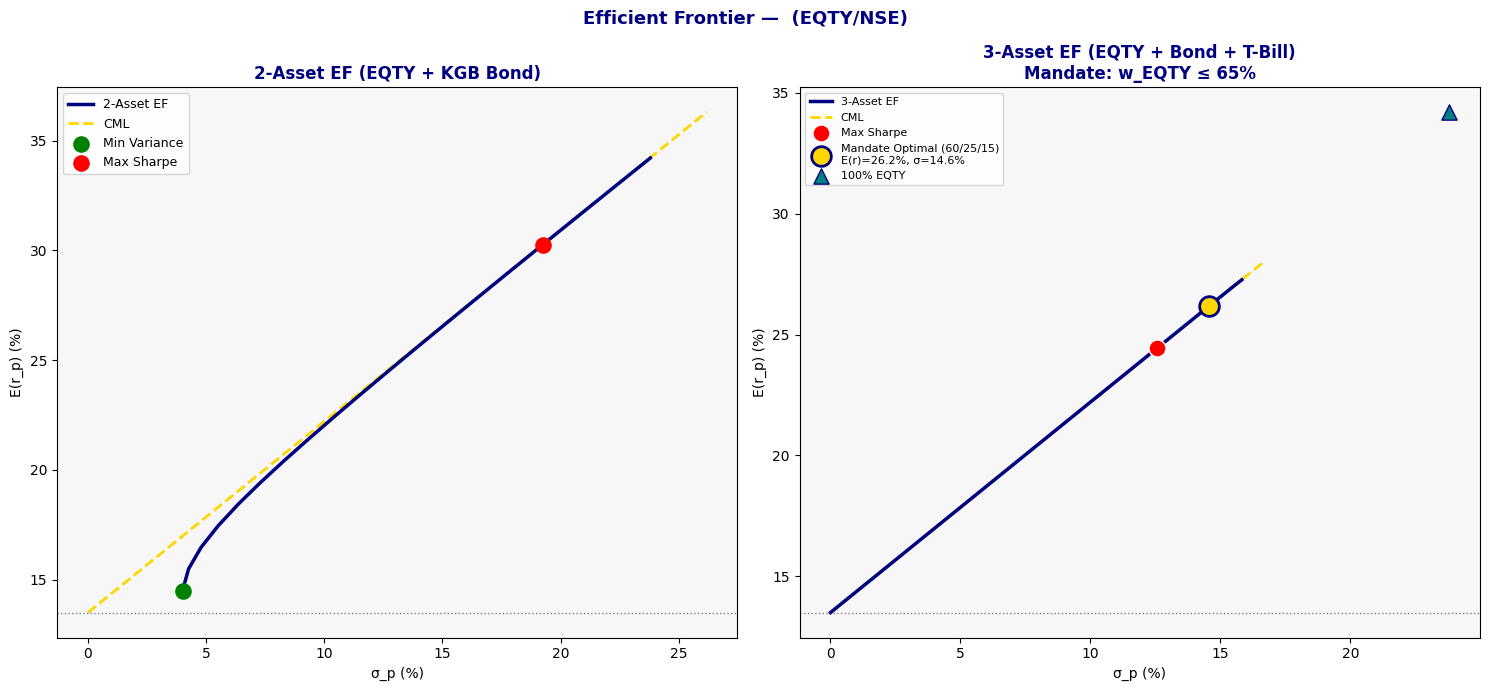

In [90]:
# VISUALISATION 
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.suptitle('Efficient Frontier —  (EQTY/NSE)', fontsize=13,
             fontweight='bold', color=NAVY)

# Left: 2-asset
ax1 = axes[0]; ax1.set_facecolor(LIGHT)
ax1.plot([s*100 for s in ef2_s], [r*100 for r in ef2_r],
         color=NAVY, linewidth=2.5, label='2-Asset EF', zorder=3)
idx_sh = np.argmax(ef2_sh)
cml_s = np.linspace(0, max(ef2_s)*100*1.1, 100)
cml_r = RF*100 + (ef2_r[idx_sh]-RF)/ef2_s[idx_sh] * (cml_s/100)*100
ax1.plot(cml_s, cml_r, color=GOLD, linewidth=2, linestyle='--', label='CML')
ax1.scatter([ef2_s[np.argmin(ef2_s)]*100],[ef2_r[np.argmin(ef2_s)]*100],
            color=GREEN, s=120, zorder=6, label='Min Variance')
ax1.scatter([ef2_s[idx_sh]*100],[ef2_r[idx_sh]*100], color=RED, s=120, zorder=6, label='Max Sharpe')
ax1.axhline(RF*100, color='gray', linestyle=':', linewidth=1)
ax1.set_xlabel('σ_p (%)'); ax1.set_ylabel('E(r_p) (%)'); ax1.legend(fontsize=9)
ax1.set_title('2-Asset EF (EQTY + KGB Bond)', fontweight='bold', color=NAVY)

# Right: 3-asset
ax2 = axes[1]; ax2.set_facecolor(LIGHT)
ax2.plot(ef3_s, ef3_r, color=NAVY, linewidth=2.5, label='3-Asset EF', zorder=3)
cml2_s = np.linspace(0, max(ef3_s)*1.05, 100)
r_o, s_o = pret(w_opt), pvol(w_opt)
cml2_r = RF*100 + (r_o-RF)/s_o * (np.array(cml2_s)/100) * 100
ax2.plot(cml2_s, cml2_r, color=GOLD, linewidth=2, linestyle='--', label='CML')
ax2.scatter([pvol(w_tan)*100],[pret(w_tan)*100], color=RED, s=150, zorder=6,
            edgecolors='white', label='Max Sharpe')
ax2.scatter([s_o*100],[r_o*100], color=GOLD, s=200, zorder=7, edgecolors=NAVY, linewidth=2,
            label=f'Mandate Optimal (60/25/15)\nE(r)={r_o*100:.1f}%, σ={s_o*100:.1f}%')
ax2.scatter([SIGMA_EQTY*100],[MU_EQTY*100], marker='^', color=TEAL, s=120, zorder=6,
            edgecolors=NAVY, label='100% EQTY')
ax2.axhline(RF*100, color='gray', linestyle=':', linewidth=1)
ax2.set_xlabel('σ_p (%)'); ax2.set_ylabel('E(r_p) (%)'); ax2.legend(fontsize=8)
ax2.set_title('3-Asset EF (EQTY + Bond + T-Bill)\nMandate: w_EQTY ≤ 65%', fontweight='bold', color=NAVY)

plt.tight_layout()
plt.show()


## 🛡️ Step 10  Value at Risk (VaR) & CVaR

| Method | Formula | Note |
|--------|---------|------|
| **Parametric VaR** | $VaR = -(\mu_d + z_\alpha \sigma_d)$ | Assumes normality |
| **Historical VaR** | $VaR = -Q_\alpha(r)$ | Non-parametric, uses actual data |
| **CVaR / ES** | $CVaR = -E[r \mid r \le -VaR]$ | Average of tail losses |

> CVaR ≥ VaR always. CVaR is the more conservative measure.


In [91]:
# SETUP 
PORTFOLIO_VALUE = 1_000_000   # KES 1,000,000
CONF_LEVELS     = [0.90, 0.95, 0.99]

r_daily    = returns['Return_Arith']
mu_d_var   = r_daily.mean()
sigma_d_var= r_daily.std()

#  METHOD 1: PARAMETRIC VaR
print("METHOD 1 — PARAMETRIC VaR (Normal Distribution)")
print(f"  μ_d = {mu_d_var*100:.4f}%,  σ_d = {sigma_d_var*100:.4f}%")
print()
pvar_res = {}
for cl in CONF_LEVELS:
    z        = stats.norm.ppf(1 - cl)
    var_pct  = -(mu_d_var + z * sigma_d_var)
    var_kes  = var_pct * PORTFOLIO_VALUE
    pvar_res[cl] = {'pct': var_pct, 'kes': var_kes}
    print(f"  {cl*100:.0f}%: z={z:.4f}, VaR={var_pct*100:.4f}%, KES {var_kes:,.0f}")

#  METHOD 2: HISTORICAL VaR
print("\nMETHOD 2 — HISTORICAL VaR (Empirical)")
hvar_res = {}
for cl in CONF_LEVELS:
    var_pct  = -r_daily.quantile(1 - cl)
    var_kes  = var_pct * PORTFOLIO_VALUE
    hvar_res[cl] = {'pct': var_pct, 'kes': var_kes}
    print(f"  {cl*100:.0f}%: VaR={var_pct*100:.4f}%, KES {var_kes:,.0f}")

#  METHOD 3: CVaR / EXPECTED SHORTFALL 
print("\nMETHOD 3 — CVaR / EXPECTED SHORTFALL")
cvar_res = {}
for cl in CONF_LEVELS:
    threshold   = r_daily.quantile(1 - cl)
    tail_losses = r_daily[r_daily <= threshold]
    cvar_pct    = -tail_losses.mean()
    cvar_kes    = cvar_pct * PORTFOLIO_VALUE
    cvar_res[cl] = {'pct': cvar_pct, 'kes': cvar_kes}
    print(f"  {cl*100:.0f}%: CVaR={cvar_pct*100:.4f}%, KES {cvar_kes:,.0f}  (from {len(tail_losses)} tail obs.)")

#  COMPARISON TABLE
print("\nCOMPARISON AT 95% CONFIDENCE (KES 1M portfolio):")
comp_df = pd.DataFrame({
    'Method':    ['Parametric VaR (Normal)', 'Historical VaR (Empirical)', 'CVaR / Expected Shortfall'],
    'VaR/CVaR %': [f'{pvar_res[0.95]["pct"]*100:.4f}%',
                   f'{hvar_res[0.95]["pct"]*100:.4f}%',
                   f'{cvar_res[0.95]["pct"]*100:.4f}%'],
    'KES (1M)':  [f'{pvar_res[0.95]["kes"]:,.0f}',
                  f'{hvar_res[0.95]["kes"]:,.0f}',
                  f'{cvar_res[0.95]["kes"]:,.0f}']
})
display(comp_df.set_index('Method'))


METHOD 1 — PARAMETRIC VaR (Normal Distribution)
  μ_d = 0.1357%,  σ_d = 1.4989%

  90%: z=-1.2816, VaR=1.7852%, KES 17,852
  95%: z=-1.6449, VaR=2.3298%, KES 23,298
  99%: z=-2.3263, VaR=3.3513%, KES 33,513

METHOD 2 — HISTORICAL VaR (Empirical)
  90%: VaR=1.2139%, KES 12,139
  95%: VaR=1.9391%, KES 19,391
  99%: VaR=3.9888%, KES 39,888

METHOD 3 — CVaR / EXPECTED SHORTFALL
  90%: CVaR=2.4907%, KES 24,907  (from 50 tail obs.)
  95%: CVaR=3.5098%, KES 35,098  (from 25 tail obs.)
  99%: CVaR=6.2138%, KES 62,138  (from 5 tail obs.)

COMPARISON AT 95% CONFIDENCE (KES 1M portfolio):


,VaR/CVaR %,KES (1M)
Method,,
Parametric VaR (Normal),2.3298%,"23,298"
Historical VaR (Empirical),1.9391%,"19,391"
CVaR / Expected Shortfall,3.5098%,"35,098"


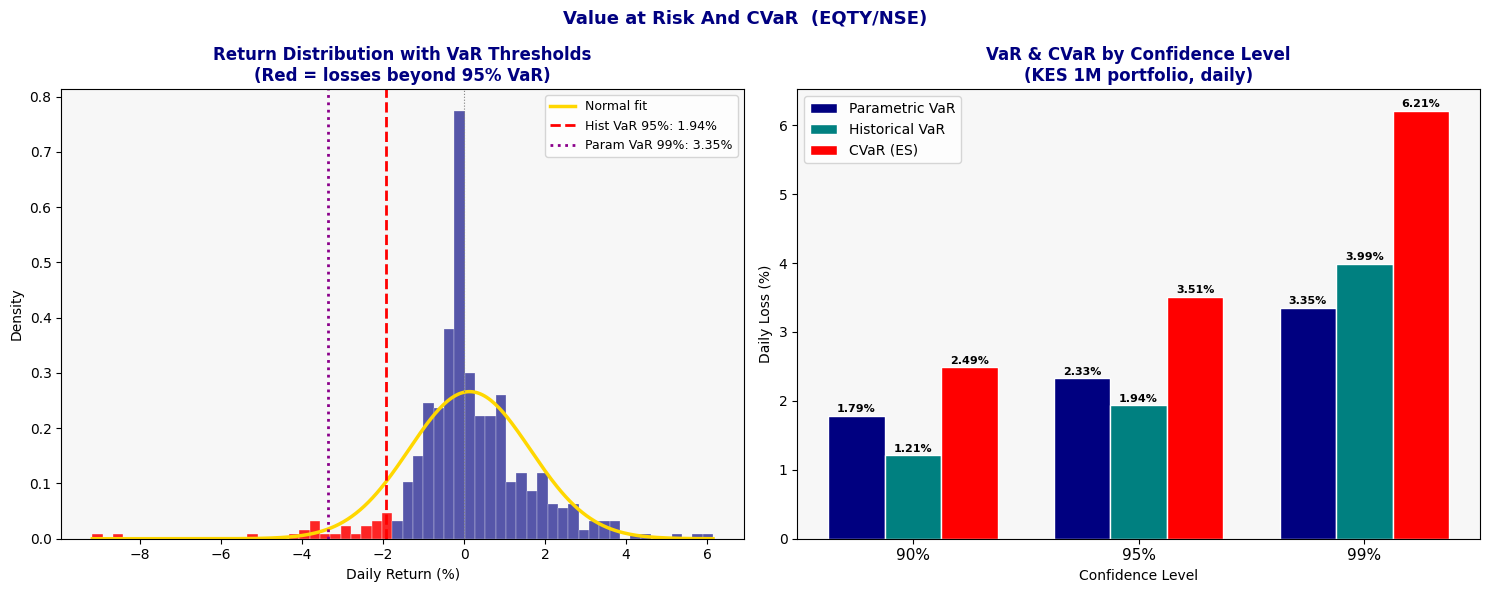

In [92]:
#  VISUALISATION
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Value at Risk And CVaR  (EQTY/NSE)', fontsize=13,
             fontweight='bold', color=NAVY)

# Left: return distribution with VaR shading
ax1 = axes[0]; ax1.set_facecolor(LIGHT)
var_threshold_95 = -hvar_res[0.95]['pct']*100

n_h, bins_h, patches_h = ax1.hist(r_daily*100, bins=60, color=NAVY, alpha=0.65,
                                    edgecolor='white', linewidth=0.3, density=True)
for patch, left in zip(patches_h, bins_h[:-1]):
    if left < var_threshold_95:
        patch.set_facecolor(RED); patch.set_alpha(0.85)

x_n = np.linspace(r_daily.min()*100, r_daily.max()*100, 300)
ax1.plot(x_n, stats.norm.pdf(x_n, mu_d_var*100, sigma_d_var*100),
         color=GOLD, linewidth=2.5, label='Normal fit')
ax1.axvline(var_threshold_95, color=RED, linestyle='--', linewidth=2,
            label=f'Hist VaR 95%: {hvar_res[0.95]["pct"]*100:.2f}%')
ax1.axvline(-pvar_res[0.99]['pct']*100, color='#8B008B', linestyle=':', linewidth=2,
            label=f'Param VaR 99%: {pvar_res[0.99]["pct"]*100:.2f}%')
ax1.axvline(0, color='gray', linewidth=0.8, linestyle=':')
ax1.set_xlabel('Daily Return (%)'); ax1.set_ylabel('Density')
ax1.set_title('Return Distribution with VaR Thresholds\n(Red = losses beyond 95% VaR)',
              fontweight='bold', color=NAVY)
ax1.legend(fontsize=9)

# Right: grouped bar — VaR/CVaR across confidence levels
ax2 = axes[1]; ax2.set_facecolor(LIGHT)
cls_labels = ['90%', '95%', '99%']
pvars = [pvar_res[c]['pct']*100 for c in CONF_LEVELS]
hvars = [hvar_res[c]['pct']*100 for c in CONF_LEVELS]
cvars = [cvar_res[c]['pct']*100 for c in CONF_LEVELS]
x_pos = np.arange(len(CONF_LEVELS))
w_b   = 0.25
ax2.bar(x_pos - w_b, pvars, width=w_b, label='Parametric VaR', color=NAVY, edgecolor='white')
ax2.bar(x_pos,       hvars, width=w_b, label='Historical VaR',  color=TEAL, edgecolor='white')
ax2.bar(x_pos + w_b, cvars, width=w_b, label='CVaR (ES)',        color=RED,  edgecolor='white')
ax2.set_xticks(x_pos); ax2.set_xticklabels(cls_labels, fontsize=11)
ax2.set_xlabel('Confidence Level'); ax2.set_ylabel('Daily Loss (%)')
ax2.set_title('VaR & CVaR by Confidence Level\n(KES 1M portfolio, daily)',
              fontweight='bold', color=NAVY)
ax2.legend(fontsize=10)
for rect in ax2.patches:
    ax2.text(rect.get_x()+rect.get_width()/2, rect.get_height()+0.02,
             f'{rect.get_height():.2f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()


In [95]:
#  PRINT COMPLETE SUMMARY 
summary = {
    # Step 2
    'First Price (KES)'             : f'{Equity_data["Close"].iloc[0]:.2f}',
    'Last Price (KES)'              : f'{Equity_data["Close"].iloc[-1]:.2f}',
    'Total 2yr Return'              : f'{HPR*100:.4f}%',
    # Step 4
    'Annual Return μ (×252)'        : f'{EQTY_MU*100:.4f}%',
    'Annual Volatility σ (×√252)'   : f'{EQTY_SIGMA*100:.4f}%',
    'Annual Variance σ²'            : f'{EQTY_VAR:.6f}',
    # Step 6
    'Rf (CBK T-bill Feb 2026)'      : f'{RF*100:.2f}%',
    'β (EQTY vs NSE20)'             : f'{BETA}',
    'Rm (NSE20)'                    : f'{RM*100:.2f}%',
    'CAPM E(r) = Rf+β(Rm-Rf)'      : f'{CAPM_ER*100:.4f}%',
    "Jensen's Alpha α"              : f'+{ALPHA*100:.4f}%',
    # Step 7
    'Portfolio Weights'             : '60% EQTY / 25% Bond / 15% T-Bill',
    'Portfolio E(r_p)'              : f'{PORT_R*100:.4f}%',
    'Portfolio σ_p'                 : f'{PORT_S*100:.4f}%',
    'Portfolio β_p'                 : f'{PORT_BETA:.4f}',
    # Step 8
    'Sharpe Ratio'                  : f'{SHARPE:.4f}',
    'Treynor Ratio'                 : f'{TREYNOR*100:.4f}%',
    'Information Ratio'             : f'{IR:.4f}',
    'Active Return'                 : f'{ACTIVE_R*100:.4f}%',
    # Step 10
    'Hist VaR 95% (daily, KES 1M)' : f'{hvar_res[0.95]["pct"]*100:.4f}%  /  KES {hvar_res[0.95]["kes"]:,.0f}',
    'CVaR 95% (daily, KES 1M)'     : f'{cvar_res[0.95]["pct"]*100:.4f}%  /  KES {cvar_res[0.95]["kes"]:,.0f}',
}

print("╔" + "═"*66 + "╗")
print("║  COMPLETE PORTFOLIO ANALYSIS SUMMARY  / EQTY (NSE)    ║")
print("╠" + "═"*66 + "╣")
for k, v in summary.items():
    print(f"║  {k:<38} : {v:<25}║")
print("╚" + "═"*66 + "╝")


╔══════════════════════════════════════════════════════════════════╗
║  COMPLETE PORTFOLIO ANALYSIS SUMMARY  / EQTY (NSE)    ║
╠══════════════════════════════════════════════════════════════════╣
║  First Price (KES)                      : 77.00                    ║
║  Last Price (KES)                       : nan                      ║
║  Total 2yr Return                       : nan%                     ║
║  Annual Return μ (×252)                 : 34.2040%                 ║
║  Annual Volatility σ (×√252)            : 23.7947%                 ║
║  Annual Variance σ²                     : 0.056619                 ║
║  Rf (CBK T-bill Feb 2026)               : 13.50%                   ║
║  β (EQTY vs NSE20)                      : 0.92                     ║
║  Rm (NSE20)                             : 18.00%                   ║
║  CAPM E(r) = Rf+β(Rm-Rf)                : 17.6400%                 ║
║  Jensen's Alpha α                       : +16.5640%                ║
║  Portfolio Weights   